# Delano diagrams: first order layout of a lithography lens

Delano's $y$-$\bar y$ diagram plots the height $\bar y$ of the paraxial
chief ray against the height $y$ of the paraxial marginal ray at every lens
(or surface). A system becomes a polygon, and all of its first order
properties can be read off it: powers, spacings, stop and pupils,
telecentricity, conjugates, cardinal points. The other way round, a lens can
be *drawn* as a polygon and then built from it. This is how complex systems
such as lithographic projection lenses are laid out before any surface is
bent (Delano 1963; Shack 1973; Matsuyama, Ohmura and Williamson, "The
lithographic lens: its history and evolution", Proc. SPIE 6154, 2006).

This notebook

1. reads the diagram of Caldwell's KrF lens (`DelanoDiagram.from_system()`),
2. shows the rules of the diagram with a three lens relay,
3. lays out a new KrF projection lens in the diagram: **20 elements, 1 m from
   object to wafer, magnification −0.25, NA 0.7**, telecentric on both sides,
   with a flat field (Petzval sum zero) — first as a hand drawn sketch, then
   polished with `delano.refine()`,
4. turns the thin lens layout into fused silica singlets with the same first
   order properties (`delano.thicken()`),
5. corrects the aberrations with real rays (`lens_optimization.LensOptimizer`,
   five aspheric surfaces, all lenses at least 10 mm thick at the centre
   and the edge) and checks the result.

Conventions (module `pyoptics.delano`): points $P = (\bar y, y)$, reduced
slopes $\omega = n u$, Lagrange invariant $H = n(\bar u y - u \bar y)$, as
`raytrace.Paraxial.lagrange`. Lengths in mm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import raytrace as rt
from pyoptics import lens_optimization as lo
from pyoptics.delano import DelanoDiagram, refine, thicken

plt.rcParams.update({"figure.dpi": 80, "font.size": 11})
t_start = time.time()

## 1. The diagram of a real lens

`DelanoDiagram.from_system()` takes the paraxial marginal and chief rays of a
`raytrace.System`: one point per surface vertex, plus the object and the
image point. Caldwell's all fused silica KrF lens (21 elements, NA 0.56, 4x,
1 m) as an example:

44 points: object, 42 surfaces, image; H = -6.2702 mm
powers from the corners vs. (n' - n)/R: max. difference 1.3e-16 1/mm
spaces from the triangle areas vs. the thicknesses: max. difference 7.5e-14 mm
magnification -0.25000 (paraxial -0.25000), NA 0.5359 (paraxial 0.5359), length 1000.01 mm
stop (y axis crossing) 701.8 mm behind the object, surface 30 at 701.8 mm; entrance pupil 10.0 m, exit pupil -2.6 m from the object


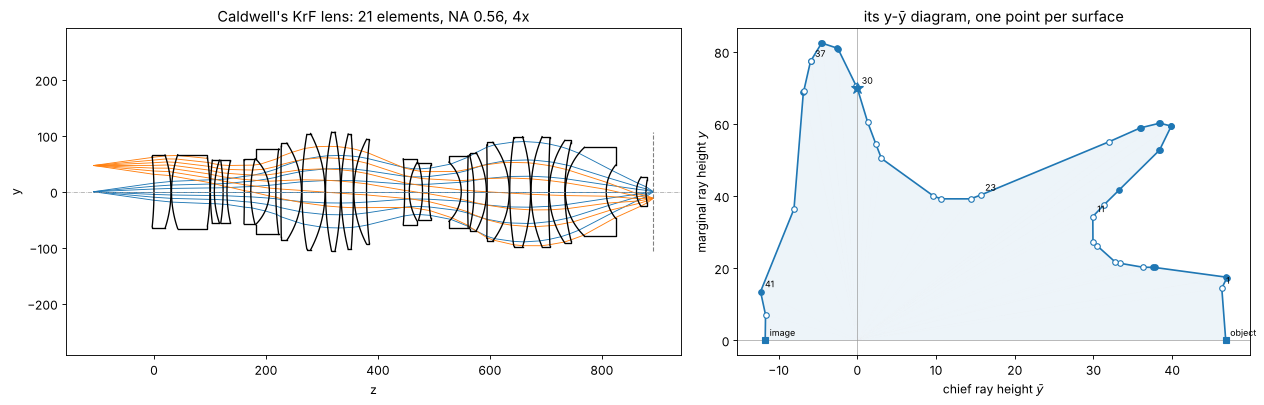

In [2]:
caldwell = rt.caldwell_krf_lens()
dc = DelanoDiagram.from_system(caldwell)
p = caldwell.paraxial()

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
caldwell.draw(axes[0], fields=[0.0, caldwell.max_field])
axes[0].set_title("Caldwell's KrF lens: 21 elements, NA 0.56, 4x")
dc.plot(axes[1], annotate=False, areas=True)
for k in [0, 1, 11, 23, 30, 37, 41, 43]:
    axes[1].annotate(dc.labels[k], (dc.ybar[k], dc.y[k]), xytext=(4, 4), textcoords="offset points",
                     fontsize=8)
axes[1].set_title("its y-ȳ diagram, one point per surface")
fig.tight_layout()

n_s = caldwell.n*caldwell.sigma
powers = np.array([s.paraxial_power(n_s[i], n_s[i + 1]) for i, s in enumerate(caldwell.surfaces)])
print(f"{len(dc)} points: object, 42 surfaces, image; H = {dc.H:.4f} mm")
print(f"powers from the corners vs. (n' - n)/R: max. difference {np.max(abs(dc.power - powers)):.1e} 1/mm")
print(f"spaces from the triangle areas vs. the thicknesses: max. difference "
      f"{np.max(abs(dc.thickness[1:-1] - [s.thickness for s in caldwell.surfaces[:-1]])):.1e} mm")
print(f"magnification {dc.magnification:.5f} (paraxial {p.magnification:.5f}), "
      f"NA {dc.NA[1]:.4f} (paraxial {p.na:.4f}), length {dc.length:.2f} mm")
pu = dc.pupils()
print(f"stop (y axis crossing) {pu.stop[0]:.1f} mm behind the object, surface 30 at "
      f"{caldwell.object_distance + caldwell.vertex_z[29]:.1f} mm; entrance pupil "
      f"{pu.entrance/1e3:.1f} m, exit pupil {pu.exit/1e3:.1f} m from the object")

How to read it:

- The polygon starts at the **object** on the $\bar y$ axis ($y = 0$, $\bar y$
  = object height 46.8 mm) and ends at the **image** ($\bar y = -11.7$ mm). It
  crosses the $y$ axis ($\bar y = 0$) once, at the **aperture stop**
  (star), here at surface 30.
- The first and the last edges are almost vertical: the chief ray is almost
  parallel to the axis in object and image space, the lens is (nearly)
  **telecentric** on both sides. The extended edges meet $\bar y = 0$ at the
  pupils, 9 m in front of and 2.6 m behind the lens.
- Every edge is a space: the shaded triangle that it spans with the origin
  has the area $H\tau/2$, with the reduced thickness $\tau = t/n$. Long air
  spaces far from the origin are large triangles; a glass element is two
  corners close together.
- Every corner is a surface: its power is the change of direction,
  $\phi_k = -(\bar\omega_{k-1}\omega_k - \omega_{k-1}\bar\omega_k)/H$. A
  convex corner (turning towards the origin) is positive (filled circles), a
  concave one negative (open circles). The same bend is a weak surface far
  from the origin and a strong one close to it.
- The shape is the classic one of lithography lenses: **bulges** (large
  beams, positive groups) and **waists** (small beams, negative groups)
  alternate. The waists correct the Petzval sum: the Petzval sum of thin
  lenses $\sum \phi_k/n_k$ does not depend on where a lens sits, but its
  contribution to the imaging, the bend of the marginal ray $y_k\phi_k$, does.
  Negative lenses in a waist (small $y$) flatten the field at little cost in
  power.

## 2. The rules, with three thin lenses

A double telecentric 4x relay of three thin lenses, drawn directly as a
polygon: object $(h, 0)$, a vertical edge up (telecentric object space), a
corner at the top, down to $(-h/4, y_3)$ and vertically down to the image
$(-h/4, 0)$. The Lagrange invariant follows from the object side NA,
$H = -\mathrm{NA}_\mathrm{obj}\,h$; `with_length()` scales all $y$ so that
the system is 1 m long (same NA, field and magnification).

focal lengths [793.2 202.4  91.1] mm; spaces [205.7 555.3 200.5  38.6] mm
thin lens system: magnification -0.2500, NA 0.7000, length 1000.0 mm, entrance/exit pupil at inf/-4.1e+17 mm (telecentric)
image of L1 in the last space: z = 1012.9 mm, magnification -0.250
image of L2 in the last space: z = 1128.5 mm, magnification -0.833


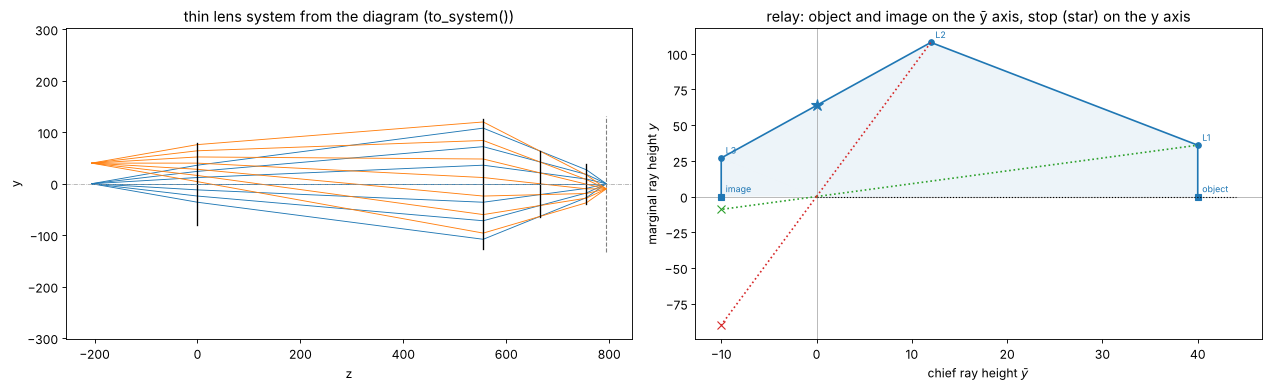

In [3]:
h = 40.0
relay = DelanoDiagram([h, h, 0.3*h, -0.25*h, -0.25*h], [0, 20, 60, 15, 0], -0.175*h,
                      labels=["object", "L1", "L2", "L3", "image"]).with_length(1000.0)
relay_system = relay.to_system(248.3e-6)
pr = relay_system.paraxial()
print("focal lengths", np.round(relay.focal_length, 1), "mm; spaces", np.round(relay.thickness, 1), "mm")
print(f"thin lens system: magnification {pr.magnification:.4f}, NA {pr.na:.4f}, "
      f"length {relay_system.object_distance + relay_system.image_z:.1f} mm, "
      f"entrance/exit pupil at {pr.ep_z:.1e}/{pr.xp_z:.1e} mm (telecentric)")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
relay_system.draw(axes[0], fields=[0.0, h])
axes[0].set_title("thin lens system from the diagram (to_system())")
relay.plot(axes[1], areas=True)
# conjugates lie on lines through the origin
axes[1].plot([0, 1.1*h], [0, 0], "k:", lw=1)
z_stop = relay.pupils().stop[0]
for k, c in [(1, "C2"), (2, "C3")]:
    z, m = relay.conjugate(3, k)
    q = m*relay.points[k]
    axes[1].plot([0, relay.ybar[k]], [0, relay.y[k]], ":", color=c)
    axes[1].plot([0, q[0]], [0, q[1]], ":", color=c)
    axes[1].plot(*q, "x", color=c, ms=8)
    print(f"image of {relay.labels[k]} in the last space: z = {z:.1f} mm, magnification {m:.3f}")
axes[1].set_title("relay: object and image on the ȳ axis, stop (star) on the y axis")
fig.tight_layout()

## 3. Specification and sketch of the new lens

The specification fixes the ends of the polygon:

| | in the diagram |
|---|---|
| magnification −0.25 | object at $(h, 0)$, image at $(-h/4, 0)$ |
| telecentric object and image space | first and last edges vertical: $\bar y_1 = h$, $\bar y_{20} = -h/4$ |
| NA 0.7 (object side 0.175) | $H = -0.175\,h$; the slopes of the first and last edges follow |
| 1 m object to wafer | scale all $y$ (`with_length()`) |
| image field radius 13.6 mm (a 26 × 8 mm scanner slit) | $h = 54.4$ mm |
| flat field | Petzval sum $\sum\phi_k/n = 0$ |

Everything in between is design. Rules for drawing the polygon:

- It has to wind around the origin in one sense (here counterclockwise):
  a step back in angle would be a negative distance.
- Distances are areas: a lens close to the origin gets little room.
- The last space is the working distance (more precisely, from the rear
  principal plane of the last lens to the wafer): $t = y_{20}/\mathrm{NA}$.
- Lenses carry diameters $2(|y| + |\bar y|)$; with 1 m length and NA 0.7 the
  largest are about 250 mm.

The sketch below has the structure of the lens of section 1 with fewer
elements: three positive field lenses (L1–L3, telecentric object space), a
first waist of three negative lenses (L4–L6), a bulge (L7–L10), a second
waist (L11–L13), and the last bulge with the stop (L14–L20), which does most
of the focusing to NA 0.7. It is written in units of $h$ for $\bar y$ and of
an arbitrary scale for $y$ (`with_length()` fixes it).

In [4]:
WL = 248.3e-6                     # KrF, mm
N_SIO2 = rt.fused_silica(248.3)
M, LENGTH, NA = -0.25, 1000.0, 0.7
R_FIELD = 13.6                    # image field radius
h = R_FIELD/abs(M)                # object height
H = -NA*abs(M)*h                  # Lagrange invariant

# (ybar/h, y) of object, L1...L20, image
SKETCH = np.array([(1, 0), (1, 0.08), (0.97, 0.15), (0.92, 0.21), (0.82, 0.21), (0.74, 0.20),
                   (0.66, 0.22), (0.60, 0.33), (0.52, 0.47), (0.42, 0.57), (0.32, 0.61),
                   (0.24, 0.53), (0.18, 0.46), (0.12, 0.45), (0.07, 0.58), (0.02, 0.74),
                   (-0.04, 0.86), (-0.10, 0.88), (-0.16, 0.74), (-0.21, 0.48), (-0.25, 0.10),
                   (-0.25, 0)])
labels = ["object"] + [f"L{k}" for k in range(1, 21)] + ["image"]
sketch = DelanoDiagram(h*SKETCH[:, 0], SKETCH[:, 1], H, labels=labels).with_length(LENGTH)


def summary(d, name):
    print(f"{name}: Petzval sum {d.petzval_sum(N_SIO2)*1e3:+.3f}/m, NA {d.NA[0]:.3f} -> {d.NA[1]:.3f}, "
          f"magnification {d.magnification:.3f}, length {d.length:.1f} mm, stop at "
          f"{d.pupils().stop[0]:.0f} mm")
    print("  f    [mm]", " ".join(f"{f:6.0f}" for f in d.focal_length))
    print("  space[mm]", " ".join(f"{t:6.1f}" for t in d.thickness))
    print("  y*phi[%] ", " ".join(f"{v:6.1f}" for v in 100*d.y[1:-1]*d.power))
    print("  semi diam", " ".join(f"{v:6.1f}" for v in d.heights()[1:-1]))


summary(sketch, "sketch")

sketch: Petzval sum +1.437/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 696 mm
  f    [mm]   2086   2419    199    156    -95   -301  20471   1575   1053    132    376    -93   -102   -883    452    343    306    528    782    535
  space[mm]   69.2   62.6   56.8   18.2    7.4   26.6   74.2   95.4   85.6   63.8   20.1   13.0   22.3   32.9   34.8   40.5   43.9   57.7   67.9   85.6   21.6
  y*phi[%]     0.6    0.9   16.0   20.3  -31.7  -11.1    0.2    4.5    8.2   69.8   21.3  -74.9  -66.5   -9.9   24.8   38.0   43.6   21.2    9.3    2.8
  semi diam   66.5   75.5   81.8   76.4   70.5   69.2   82.6   99.4  109.1  109.7   93.2   79.4   74.6   91.6  113.0  132.3  138.6  120.7   84.0   28.7


The sketch already has the intended signs and a small Petzval sum (a
Petzval radius of about 0.7 m). Its weak points are in the row "y*phi", the
bend $y_k\phi_k$ of the marginal ray at each lens (the whole lens bends it
by 0.875, from +0.175 to −0.7): L10 at the corner into the second waist and
L12, L13 in it bend it by about ±0.7 each and cancel, which costs
aberrations, while L1, L2 and L7 do almost nothing; and the spaces around
L5 and L12 are too short for real lenses.

`refine()` moves the points of the sketch (keeping the telecentric ends) to
a Petzval sum of zero, spaces of at least 25 mm, a working space of 40 mm,
semi diameters up to 125 mm and the signs of the sketch, while staying close
to it and spreading the bending of the marginal ray over the lenses. It is a
small least squares problem in the 38 free coordinates of the inner points
(seconds).

refined: Petzval sum +0.000/m, NA 0.175 -> 0.700, magnification -0.250, length 1000.0 mm, stop at 677 mm
  f    [mm]   1445   2018    727    188   -223   -123    403   1657    275    290   6282   -109   -110  -1219    331    251   2050    223    925   2354
  space[mm]   98.2   41.8   31.6   25.0   25.0   25.0   49.6  101.3  103.8   25.0   25.0   28.3   25.0   27.0   36.9   28.6   42.4   96.8   61.8   62.1   40.0
  y*phi[%]     1.2    1.2    4.0   16.8  -13.5  -26.2   12.2    4.3   32.6   29.6    1.2  -56.6  -58.5   -6.8   33.6   49.2    5.9   48.6    7.6    1.2
  semi diam   71.6   76.8   79.6   79.0   68.0   64.6   83.9  102.2  114.6  107.1   90.5   71.2   70.4   86.9  112.0  125.0  125.5  120.5   84.0   41.6
thin lens system: m = -0.25000, NA = 0.7000, length = 1000.00 mm, telecentric: pupils at -1.1e+18 and -1.2e+18 mm


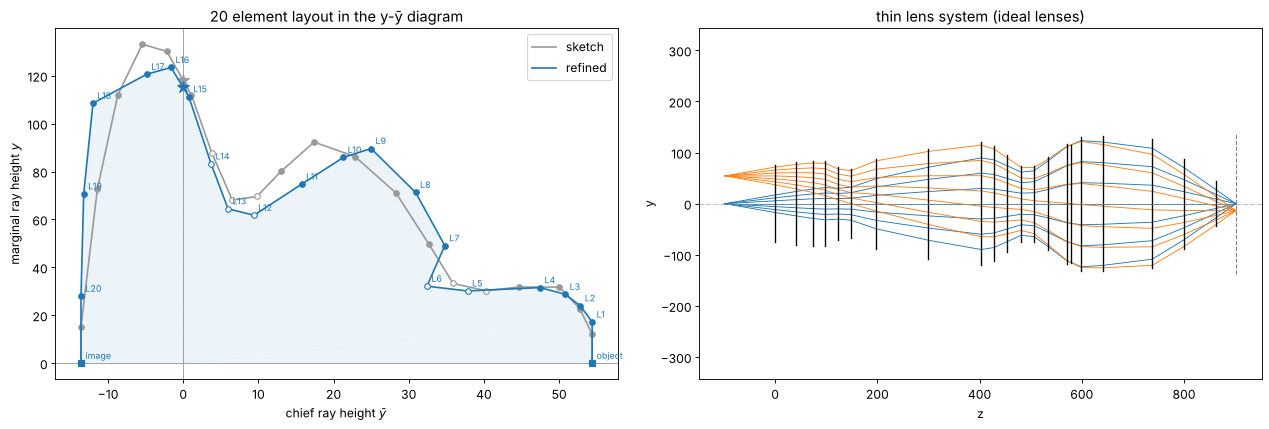

In [5]:
layout = refine(sketch, N_SIO2, min_space=25.0, spaces={-1: 40.0}, max_height=125.0, anchor=1.0)
summary(layout, "refined")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sketch.plot(axes[0], color="0.6", label="sketch", annotate=False)
layout.plot(axes[0], color="C0", label="refined", areas=True)
axes[0].legend()
axes[0].set_title("20 element layout in the y-ȳ diagram")
thin = layout.to_system(WL)
thin.draw(axes[1], fields=[0.0, h])
axes[1].set_title("thin lens system (ideal lenses)")
fig.tight_layout()
pt = thin.paraxial()
print(f"thin lens system: m = {pt.magnification:.5f}, NA = {pt.na:.4f}, "
      f"length = {thin.object_distance + thin.image_z:.2f} mm, telecentric: "
      f"pupils at {pt.ep_z:.1e} and {pt.xp_z:.1e} mm")

## 4. Thick lenses with the same first order properties

`thicken()` replaces every thin lens by a fused silica singlet of the same
power, with a centre thickness (here 0.2 × the paraxial semi diameter,
15–40 mm, the last lens 30 mm) and a shape factor
$X = (c_1 + c_2)/(c_1 - c_2)$ (here equiconvex/equiconcave, $X = 0$). The
principal planes of each singlet sit where the thin lens was, so the
paraxial rays in all air spaces stay those of the layout; only the distance
between the principal planes of each lens adds to the length, which
`length=` takes out by rescaling the diagram. The diagram of the thick
system (one point per surface) goes through the same lines as the thin one:

thick start system: m = -0.25000, NA = 0.7000, length = 1000.00 mm
Seidel sums at full field: W040 = -32503, W131 = 15709, W222 = -664, W220 = -411, W311 = 725 waves


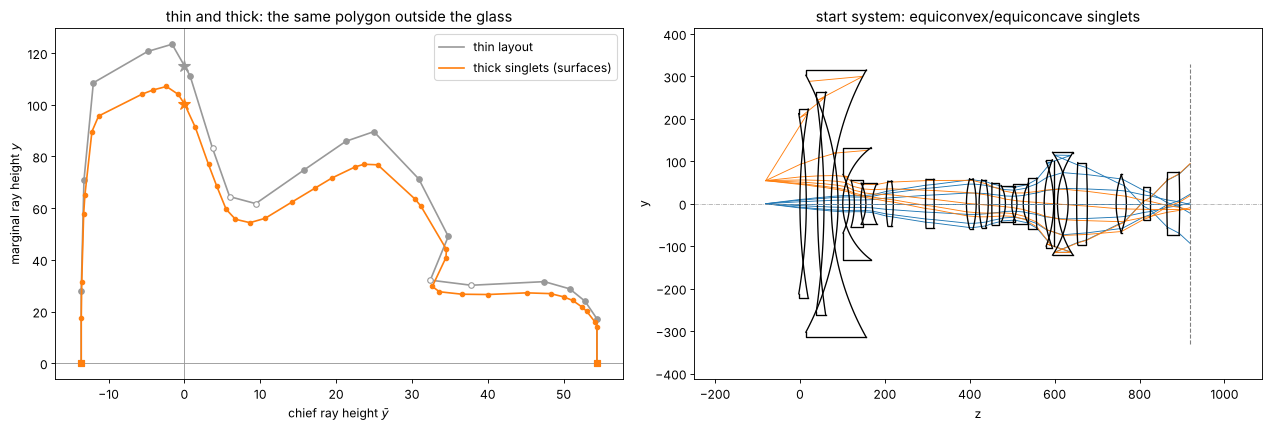

In [6]:
T = np.clip(0.2*layout.heights()[1:-1], 15, 40)
T[-1] = 30.0
start = thicken(layout, WL, rt.fused_silica, T, 0.0, length=LENGTH, check=False)
d_start = DelanoDiagram.from_system(start)
ps = start.paraxial()
print(f"thick start system: m = {ps.magnification:.5f}, NA = {ps.na:.4f}, "
      f"length = {start.object_distance + start.image_z:.2f} mm")
sd = start.seidel()
print(f"Seidel sums at full field: W040 = {sd.W040:.0f}, W131 = {sd.W131:.0f}, W222 = {sd.W222:.0f}, "
      f"W220 = {sd.W220:.0f}, W311 = {sd.W311:.0f} waves")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
layout.with_length(LENGTH).plot(axes[0], color="0.6", label="thin layout", annotate=False)
d_start.plot(axes[0], color="C1", label="thick singlets (surfaces)", annotate=False, signs=False)
axes[0].legend()
axes[0].set_title("thin and thick: the same polygon outside the glass")
start.draw(axes[1], fields=[0.0, h])
axes[1].set_title("start system: equiconvex/equiconcave singlets")
fig.tight_layout()

First order is now right, third order not at all: the lenses are not bent
yet, the spherical aberration alone is thousands of waves.

## 5. Correcting the aberrations with real rays

`LensOptimizer` varies all curvatures, all thicknesses (glass and air), the
object distance and the $r^4$, $r^6$ and $r^8$ coefficients of five
aspheric surfaces, about evenly spread from the reticle to the wafer (the
rear of L2, the front of L6, the rear of L10, the front of L15 next to the
stop, the rear of L19), and minimizes, by damped least squares, the
residuals of

- the transverse ray errors relative to the chief ray on four rings of the
  pupil at six fields (tolerance 0.1 µm),
- distortion against $m = -0.25$ at five fields (10 nm), image and object
  side telecentricity, the paraxial magnification,
- clearances: centre and edge thicknesses of at least 10 mm, air spaces of
  1 mm, 30 mm in front of the reticle, 8 mm working distance, checked at the
  rim of the full beam.

The length stays 1 m (the image distance is solved) and the object side
NA 0.175 (the stop size is solved). A local optimizer cannot open a lens
from scratch to NA 0.7 and the full field, the rays at the rim of the pupil
fail (they miss surfaces or are totally reflected). As in end-to-end lens
design by gradient descent, the aperture and the field are opened in
stages, here in three phases:

1. 40 %, 60 %, 80 % and 90 % of the NA and the field, telecentricity to
   1 mrad;
2. 90 % to 100 % in small steps (a large last step loses the rim rays of
   the full field), telecentricity to 0.2 mrad;
3. at full aperture and field, telecentricity and distortion of the
   **real** chief ray (`aim=True`). The ray traces of the optimizer aim at
   the paraxial entrance pupil (no ray aiming, 20 times faster), and at
   NA 0.7 the pupil aberrations put the ray that starts towards it tens of
   mrad away from the ray through the centre of the stop; `aim=True` aims
   the chief ray alone at the stop.

The full run takes about two and a half hours; it is reproduced in the cell
below with `RUN_FULL = True`. Otherwise only a few steps of the first stage
run here and the result of the full run is loaded from
`raytrace.delano_krf_lens()`, which stores it.

In [7]:
RUN_FULL = False


def operands(telecentricity, aim):
    return [lo.ray_errors(fields=(0, 0.35, 0.6, 0.8, 0.9, 1), tolerance=1e-4),
            lo.distortion(M, fields=(0.25, 0.5, 0.7, 0.85, 1), aim=aim),
            lo.image_telecentricity(tolerance=telecentricity, aim=aim),
            lo.object_telecentricity(tolerance=telecentricity, aim=aim),
            lo.paraxial_target("magnification", M, 1e-5),
            lo.clearances(min_center=10.0, min_edge=10.0, min_image_distance=8.0,
                          min_object_distance=30.0)]


lens_surfaces = [i for i in range(len(start.surfaces)) if start.n[i] != start.n[i + 1]]
ASPHERES = [lens_surfaces[2*k + j] for k, j in [(1, 1), (5, 0), (9, 1), (14, 0), (18, 1)]]
phases = [(operands(1e-3, False), [(a, a) for a in (0.4, 0.6, 0.8, 0.9)], 150),
          (operands(2e-4, False), [(a, a) for a in (0.9, 0.94, 0.97, 1.0)], 200),
          (operands(2e-4, True), [(1.0, 1.0)]*3, 150)]
start.ray_aiming = False  # paraxial pupil aiming is much faster
t0 = time.time()
system, log = start, []
for ops, stages, nfev in (phases if RUN_FULL else [(phases[0][0], phases[0][1][:1], 5)]):
    opt = lo.LensOptimizer(system, ops, thicknesses=list(range(len(system.surfaces) - 1)),
                           object_distance=True, length=LENGTH, object_na=NA*abs(M),
                           aspheres=ASPHERES, asphere_orders=(4, 6, 8))
    result = opt.run(stages=stages, max_nfev=nfev)
    system = result.system
    log += result.stages
design = system if RUN_FULL else rt.delano_krf_lens()
print(f"aspheres on surfaces {[i + 1 for i in ASPHERES]}; {len(opt.x)} variables, "
      f"{len(opt.residuals())} residuals, {time.time() - t0:.0f} s")
for na_f, field_f, cost, nfev in log:
    print(f"  stage at {na_f:.0%} NA, {field_f:.0%} field: cost {cost:.4g} after {nfev} evaluations")

aspheres on surfaces [4, 11, 20, 29, 39]; 96 variables, 308 residuals, 16 s
  stage at 40% NA, 40% field: cost 8.194e+09 after 5 evaluations


## 6. The corrected lens

design: m = -0.25000, NA = 0.7000, length = 1000.000 mm, working distance 8.0 mm, object distance 30.0 mm, 699 mm of glass, largest semi diameter 126 mm
thinnest centre 10.0 mm, largest clearance violation 0.00 mm


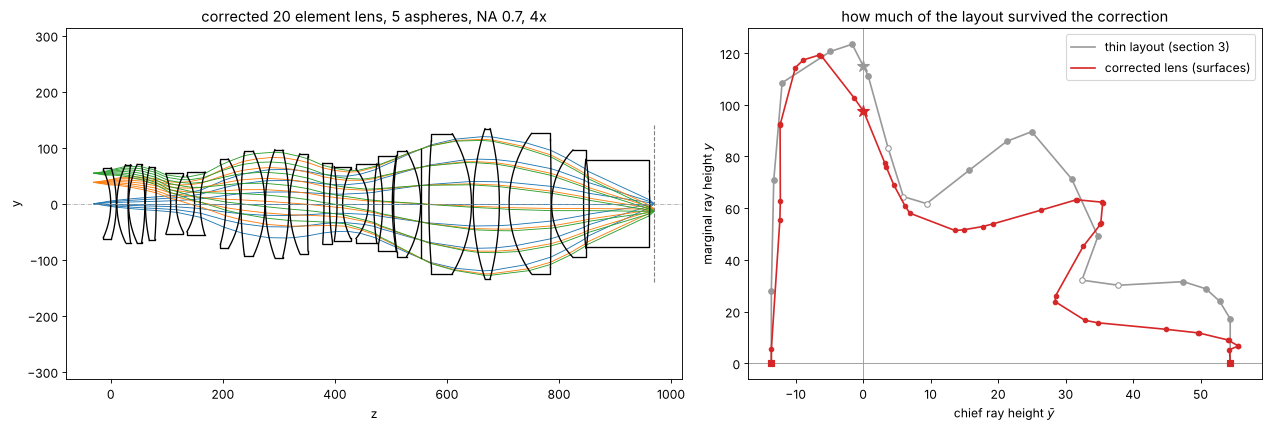

In [8]:
design.ray_aiming = True
pd = design.paraxial()
d_design = DelanoDiagram.from_system(design)
glass = [i for i in range(len(design.surfaces)) if not design._is_gap(design.n[i + 1])]
print(f"design: m = {pd.magnification:.5f}, NA = {pd.na:.4f}, "
      f"length = {design.object_distance + design.image_z:.3f} mm, working distance "
      f"{design.surfaces[-1].thickness:.1f} mm, object distance {design.object_distance:.1f} mm, "
      f"{sum(design.surfaces[i].thickness for i in glass):.0f} mm of glass, "
      f"largest semi diameter {np.max(d_design.heights()):.0f} mm")
edge = lo.clearances(min_center=10.0, min_edge=10.0, margin=1.0, tolerance=1.0)(design)
print(f"thinnest centre {min(design.surfaces[i].thickness for i in glass):.1f} mm, "
      f"largest clearance violation {np.max(edge):.2f} mm")

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
design.draw(axes[0], fields=[0.0, 0.7*h, h])
axes[0].set_title("corrected 20 element lens, 5 aspheres, NA 0.7, 4x")
layout.plot(axes[1], color="0.6", label="thin layout (section 3)", annotate=False)
d_design.plot(axes[1], color="C3", label="corrected lens (surfaces)", annotate=False, signs=False)
axes[1].legend()
axes[1].set_title("how much of the layout survived the correction")
fig.tight_layout()

r =  0.00 mm: RMS wavefront 0.095 waves, spot 0.30 µm rms, distortion    +0 nm, chief ray  +0.0 /  +0.0 mrad (object / image)
r =  1.36 mm: RMS wavefront 0.099 waves, spot 0.31 µm rms, distortion    +9 nm, chief ray  -0.4 /  -0.1 mrad (object / image)
r =  2.72 mm: RMS wavefront 0.122 waves, spot 0.34 µm rms, distortion   +16 nm, chief ray  -0.7 /  -0.2 mrad (object / image)
r =  4.08 mm: RMS wavefront 0.167 waves, spot 0.37 µm rms, distortion   +17 nm, chief ray  -1.0 /  -0.2 mrad (object / image)
r =  5.44 mm: RMS wavefront 0.218 waves, spot 0.40 µm rms, distortion   +10 nm, chief ray  -1.3 /  -0.3 mrad (object / image)
r =  6.80 mm: RMS wavefront 0.246 waves, spot 0.41 µm rms, distortion    -4 nm, chief ray  -1.4 /  -0.3 mrad (object / image)
r =  8.16 mm: RMS wavefront 0.235 waves, spot 0.38 µm rms, distortion   -20 nm, chief ray  -1.5 /  -0.3 mrad (object / image)
r =  9.52 mm: RMS wavefront 0.189 waves, spot 0.37 µm rms, distortion   -25 nm, chief ray  -1.4 /  -0.3 mrad (object /

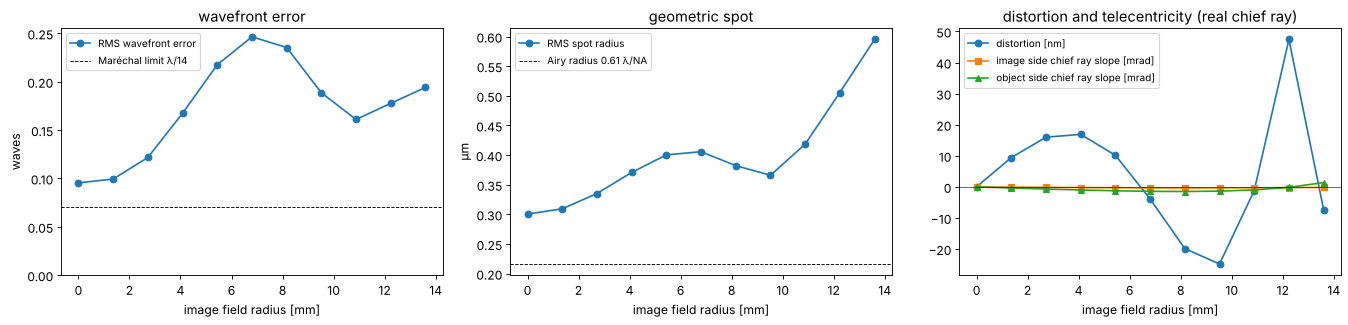

In [9]:
fields = np.linspace(0, 1, 11)
rms = np.array([design.rms_opd(field=f*h, N=48) for f in fields])
spots = [design.spot_diagram(f*h, N=21) for f in fields]
dist, tele, tele_obj = [], [], []
for f in fields:
    rays = design.rays(f*h, 0.0, 0.0)  # the chief ray, aimed at the centre of the stop
    d0 = np.reshape(rays.directions, (-1, 3))[0]
    I, D = design._image_hits(design.trace(rays, clip=False))
    dist.append((I[0, 1] - M*f*h)*1e6)
    tele.append(D[0, 1]/D[0, 2]*1e3)
    tele_obj.append(d0[1]/d0[2]*1e3)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
r_img = fields*R_FIELD
axes[0].plot(r_img, rms, "o-", label="RMS wavefront error")
axes[0].axhline(0.07, color="k", ls="--", lw=0.8, label="Maréchal limit λ/14")
axes[0].set_xlabel("image field radius [mm]"); axes[0].set_ylabel("waves")
axes[0].set_ylim(0, None); axes[0].legend(fontsize=9); axes[0].set_title("wavefront error")
axes[1].plot(r_img, [s.rms*1e3 for s in spots], "o-", label="RMS spot radius")
axes[1].axhline(0.61*WL*1e3/NA, color="k", ls="--", lw=0.8, label="Airy radius 0.61 λ/NA")
axes[1].set_xlabel("image field radius [mm]"); axes[1].set_ylabel("µm"); axes[1].legend(fontsize=9)
axes[1].set_title("geometric spot")
axes[2].plot(r_img, dist, "o-", label="distortion [nm]")
axes[2].plot(r_img, tele, "s-", label="image side chief ray slope [mrad]")
axes[2].plot(r_img, tele_obj, "^-", label="object side chief ray slope [mrad]")
axes[2].axhline(0, color="k", lw=0.5); axes[2].set_xlabel("image field radius [mm]")
axes[2].legend(fontsize=9); axes[2].set_title("distortion and telecentricity (real chief ray)")
fig.tight_layout()
for f, w, s, dd, t, to in zip(fields, rms, spots, dist, tele, tele_obj):
    print(f"r = {f*R_FIELD:5.2f} mm: RMS wavefront {w:.3f} waves, spot {s.rms*1e3:.2f} µm rms, "
          f"distortion {dd:+5.0f} nm, chief ray {to:+5.1f} / {t:+5.1f} mrad (object / image)")

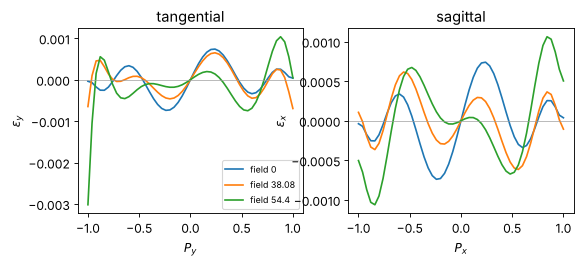

In [10]:
axes = design.plot_ray_fan(fields=[0.0, 0.7*h, h])

## 7. What the diagram did and what it did not

- **First order is exact.** The layout of section 3 fixes magnification,
  NA, length, telecentricity and the flat Petzval field before a single
  surface is bent; thickening keeps all of it, and the optimizer only
  has to hold it (the solves for length and NA, small residuals for
  telecentricity and magnification).
- **The correction moves the layout.** The diagram of the corrected lens
  (section 6) keeps the telecentric ends, the strong last bulge around the
  stop and both waists, but it lowers the bulge between them to almost the
  height of the waists (marginal ray heights of 50–65 instead of 30–90 in
  the units of the plot) and pulls the first waist closer to the reticle:
  the optimizer spread the negative power of the waists over a long, slim
  middle section.
- **20 elements and 5 aspheres get close to the diffraction limit.** The
  design is corrected to 0.10–0.25 waves RMS over the field (0.3–0.6 µm
  spots), 1.4–3.5 times the Maréchal limit, with distortions below 50 nm
  and a real chief ray that leaves the reticle at less than 1.5 mrad and
  meets the wafer at less than 0.3 mrad: telecentric on both sides. The
  13 spherical elements of an earlier version of this notebook reached only
  0.5–1.3 waves and gave up the object side telecentricity (170 mrad) for
  it. Both the extra lenses and the aspheres count: the same 20 elements
  without aspheres stopped at 0.3–0.6 waves (and 50–60 mrad off
  telecentric).
- **Telecentricity of which ray?** Without ray aiming the "chief ray" of the
  optimizer starts towards the paraxial entrance pupil; at NA 0.7 the
  pupil aberrations put it tens of mrad away from the ray through the centre
  of the stop, so a design that was telecentric for the optimizer was not
  telecentric at all. The `aim=True` operands of phase 3 trace the real
  chief ray (aimed at the stop centre by Newton's method, all fields in one
  trace), at about twice the cost of an evaluation.
- **Not a production design.** Real KrF lenses of this NA have about 30
  elements; the last element here is a 108 mm thick block in front of the
  wafer, many air spaces sit at the 1 mm limit and many lenses at the
  10 mm limit, and nothing was toleranced. Distortion and wavefront error
  are only controlled at the sampled fields (the distortion peaks at 47 nm
  between the 85 % and the full field).

Exercises: sample more fields for distortion; give the optimizer more
aspheres or other surfaces for them (`aspheres=` of `LensOptimizer`);
split the block in front of the wafer (draw another lens into the
sketch); use a smaller field or a lower NA and see how the residual
wavefront error drops; follow the diagram through the stages of the
optimization (`DelanoDiagram.from_system()`).

In [11]:
print(f"run time {time.time() - t_start:.0f} s")

run time 52 s
